# Resume decoder training from step 7,500 to 15,000

**Architecture:** RoPE + MQA + RMSNorm + SwiGLU.

In [1]:
!pip install ijson bert-score --break-system-packages -q
import os, math, json, time, random, zipfile, csv, glob, shutil, gc, subprocess, re
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from huggingface_hub import hf_hub_download

from kaggle_secrets import UserSecretsClient
hf_token = UserSecretsClient().get_secret("HuggingFace")

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NUM_GPUS = torch.cuda.device_count()
print(DEVICE, NUM_GPUS)

def find_files(name, root="/kaggle/input"):
    """Robust recursive search (follows symlinks, unlike glob '**' on older Pythons)."""
    hits = []
    for dp, _, fns in os.walk(root, followlinks=True):
        if name in fns: hits.append(os.path.join(dp, name))
    return sorted(hits)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.9/149.9 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 2.4 MB/s eta 0:00:00
cuda 2


In [2]:
SEED = 42
random.seed(SEED); torch.manual_seed(SEED)

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
DATA_SOURCES = [
    "Phase_1_Pretraining/Train/train_supreme_court.json",
    "Phase_1_Pretraining/Train/train_acts.json",
    "Phase_1_Pretraining/Train/train_high_courts.json",
    "Phase_1_Pretraining/Train/train_tribunals.json",
]
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

ARCH_NAME = "rope_mqa_swiglu"
BPE_VOCAB_SIZE = 12000
BPE_TRAIN_CHARS = 8000000
MAX_BPE_WORDS = 100000
TRAIN_TOKENS = 300000000                                                                                   
VAL_TOKENS = 10000000
BLOCK_SIZE = 512

                                                                                  
                                                                  
MICRO_BATCH_SIZE = 4
GRAD_ACCUM_STEPS = 2

TRAIN_STEPS = 15000                                
EVAL_EVERY = 500
WARMUP_STEPS = 200
LR = 3e-4
WEIGHT_DECAY = 0.1
TRAIN_TIME_BUDGET_H = 8.0                                                                                                     

D_MODEL, N_LAYERS, N_HEADS, D_FF, DROPOUT = 768, 12, 12, 3072, 0.1
KV_HEADS, ROPE_BASE = 1, 10000.0

TARGET_GENERATION_WORDS = 128
MAX_GENERATION_TOKENS = 400                                                                    
GEN_BATCH = 16
CHECKPOINT_EVERY = 250

_data_tag = "-".join(s.split("/")[-1].replace(".json", "") for s in DATA_SOURCES)
RUN_ID = f"{ARCH_NAME}_{_data_tag}"
OUTPUT_DIR = f"/kaggle/working/cs781_phase1/{RUN_ID}"
os.makedirs(OUTPUT_DIR, exist_ok=True)

TOKENIZER_PATH = os.path.join(OUTPUT_DIR, "bpe_tokenizer.json")
CHECKPOINT_PATH = os.path.join(OUTPUT_DIR, "checkpoint.pt")
MODEL_PATH = os.path.join(OUTPUT_DIR, "model.pt")
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "loss.png")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")
HELDOUT_TRUTH_PATH = os.path.join(OUTPUT_DIR, "heldout_truth.json")
HELDOUT_PRED_PATH = os.path.join(OUTPUT_DIR, "heldout_prediction.json")
LOG_PATH = "/kaggle/working/cs781_phase1/experiment_log.csv"
EVAL_SCRIPT = "/kaggle/input/datasets/adityakumar344/evaluate-phase1-script/evaluate_phase1.py"
_found = find_files("evaluate_phase1.py")                                       
if _found: EVAL_SCRIPT = _found[0]
print("eval script:", EVAL_SCRIPT if os.path.exists(EVAL_SCRIPT) else "NOT FOUND -> will use bert_score package fallback")
print(RUN_ID)

eval script: NOT FOUND -> will use bert_score package fallback
rope_mqa_swiglu_train_supreme_court-train_acts-train_high_courts-train_tribunals


In [3]:
                                                          
                                                                                                                                                             
SRC_DIR_OVERRIDE = None
SRC_DIR, INIT_CKPT = None, None
_cks = [f"{SRC_DIR_OVERRIDE}/checkpoint.pt"] if SRC_DIR_OVERRIDE else find_files("checkpoint.pt")
if not _cks: print("No checkpoint.pt under /kaggle/input. Contents:", os.listdir("/kaggle/input"))
for ck in _cks:
    d = os.path.dirname(ck)
    print("found:", ck, "| tokenizer:", os.path.exists(f"{d}/bpe_tokenizer.json"), "| corpus:", os.path.exists(f"{d}/tokenized_corpus.pt"))
    if os.path.exists(f"{d}/bpe_tokenizer.json") and os.path.exists(f"{d}/tokenized_corpus.pt") and SRC_DIR is None:
        SRC_DIR, INIT_CKPT = d, ck

if not os.path.exists(CHECKPOINT_PATH):                                                                  
    assert INIT_CKPT is not None, "Attach the previous notebook OUTPUT as an Input (needs checkpoint.pt + bpe_tokenizer.json + tokenized_corpus.pt)."

if SRC_DIR is not None:
    shutil.copy(f"{SRC_DIR}/bpe_tokenizer.json", TOKENIZER_PATH)
    TOKENIZED_CACHE_PATH = f"{SRC_DIR}/tokenized_corpus.pt"                                             
else:
    TOKENIZED_CACHE_PATH = os.path.join(OUTPUT_DIR, "tokenized_corpus.pt")
    assert os.path.exists(TOKENIZED_CACHE_PATH) and os.path.exists(TOKENIZER_PATH), "Missing tokenizer/corpus cache"
print("SRC_DIR:", SRC_DIR); print("INIT_CKPT:", INIT_CKPT)

found: /kaggle/input/datasets/parth1223/decoder-output/cs781_phase1/rope_mqa_swiglu_train_supreme_court-train_acts-train_high_courts-train_tribunals/checkpoint.pt | tokenizer: True | corpus: True
SRC_DIR: /kaggle/input/datasets/parth1223/decoder-output/cs781_phase1/rope_mqa_swiglu_train_supreme_court-train_acts-train_high_courts-train_tribunals
INIT_CKPT: /kaggle/input/datasets/parth1223/decoder-output/cs781_phase1/rope_mqa_swiglu_train_supreme_court-train_acts-train_high_courts-train_tribunals/checkpoint.pt


In [4]:
                                                                                                               
def download(path):
    return hf_hub_download(repo_id=HF_DATASET_REPO, filename=path, repo_type="dataset", token=hf_token)

train_file_paths = [download(p) for p in DATA_SOURCES]
test_file_path = download(TEST_FILE)

import ijson
CHARS_PER_TOKEN_EST = 6
CHAR_BUDGET = (TRAIN_TOKENS + VAL_TOKENS) * CHARS_PER_TOKEN_EST + BPE_TRAIN_CHARS + 5000000
MIN_RECORDS = 1000

def stream_records(path, char_budget, min_records):
    collected_chars, n = 0, 0
    with open(path, "rb") as f:
        for rec in ijson.items(f, "item"):
            yield rec
            collected_chars += len(rec.get("text", ""))
            n += 1
            if collected_chars >= char_budget and n >= min_records:
                return

per_file_budget = CHAR_BUDGET // len(train_file_paths)
per_file_min = max(MIN_RECORDS // len(train_file_paths), 300)

records = []
for p in train_file_paths:
    records.extend(stream_records(p, per_file_budget, per_file_min))
random.Random(SEED).shuffle(records)

N_HELDOUT_DOCS = 200
heldout_records = records[-N_HELDOUT_DOCS:]
print(len(records), "records;", len(heldout_records), "held-out docs")
records = None; gc.collect()                                                           

Phase_1_Pretraining/Train/train_supreme_(…): reconstructing file:   0%|          |  0.00B / 1.32GB            

Phase_1_Pretraining/Train/train_supreme_(…): downloading bytes:           |  0.00B            

Phase_1_Pretraining/Train/train_acts.jso(…): reconstructing file:   0%|          |  0.00B /  729MB            

Phase_1_Pretraining/Train/train_acts.jso(…): downloading bytes:           |  0.00B            

Phase_1_Pretraining/Train/train_high_cou(…): reconstructing file:   0%|          |  0.00B / 10.7GB            

Phase_1_Pretraining/Train/train_high_cou(…): downloading bytes:           |  0.00B            

Phase_1_Pretraining/Train/train_tribunal(…): reconstructing file:   0%|          |  0.00B / 6.48GB            

Phase_1_Pretraining/Train/train_tribunal(…): downloading bytes:           |  0.00B            

test.json:   0%|          | 0.00/3.03M [00:00<?, ?B/s]

261738 records; 200 held-out docs


0

In [5]:
class ByteLevelBPETokenizer:
    SPECIAL_TOKENS = ["<pad>", "<unk>", "<s>", "</s>"]
    def __init__(self):
        self.merges = {}
        self.id_to_bytes = {i: bytes([i]) for i in range(256)}
        self.special_to_id = {}
        for i, tok in enumerate(self.SPECIAL_TOKENS):
            tid = 256 + i
            self.special_to_id[tok] = tid
            self.id_to_bytes[tid] = tok.encode("utf-8")
    @property
    def vocab_size(self): return len(self.id_to_bytes)
    @staticmethod
    def _pair_counts(sequences):
        counts = {}
        for seq, freq in sequences:
            for pair in zip(seq, seq[1:]):
                counts[pair] = counts.get(pair, 0) + freq
        return counts
    @staticmethod
    def _apply_merge(seq, pair, new_id):
        out, i = [], 0
        while i < len(seq):
            if i < len(seq) - 1 and (seq[i], seq[i + 1]) == pair:
                out.append(new_id); i += 2
            else:
                out.append(seq[i]); i += 1
        return out
    def train(self, text, vocab_size, max_words=MAX_BPE_WORDS, verbose=True):
        num_merges = vocab_size - self.vocab_size
        if num_merges <= 0: return self
        word_freq = {}
        for word in text.split():
            word_freq[word] = word_freq.get(word, 0) + 1
        if len(word_freq) > max_words:
            word_freq = dict(sorted(word_freq.items(), key=lambda kv: -kv[1])[:max_words])
        sequences = [[list(word.encode("utf-8")), freq] for word, freq in word_freq.items()]
        next_id = self.vocab_size
        for step in range(num_merges):
            counts = self._pair_counts(sequences)
            if not counts: break
            best_pair = max(counts, key=counts.get)
            self.merges[best_pair] = next_id
            self.id_to_bytes[next_id] = self.id_to_bytes[best_pair[0]] + self.id_to_bytes[best_pair[1]]
            for entry in sequences:
                entry[0] = self._apply_merge(entry[0], best_pair, next_id)
            next_id += 1
        return self
    def encode(self, text):
        ids = []
        for word in text.split():
            seq = list(word.encode("utf-8"))
            while len(seq) > 1:
                mergeable = [p for p in zip(seq, seq[1:]) if p in self.merges]
                if not mergeable: break
                pair = min(mergeable, key=lambda p: self.merges[p])
                seq = self._apply_merge(seq, pair, self.merges[pair])
            ids.extend(seq)
            ids.append(self.special_to_id["</s>"])
        return ids
    def decode(self, ids):
        words, current = [], []
        for i in ids:
            if i == self.special_to_id["</s>"]:
                if current:
                    words.append(b"".join(self.id_to_bytes.get(int(t), b"") for t in current).decode("utf-8", errors="ignore"))
                    current = []
            else:
                current.append(i)
        if current:
            words.append(b"".join(self.id_to_bytes.get(int(t), b"") for t in current).decode("utf-8", errors="ignore"))
        return " ".join(words)
    def save(self, path):
        with open(path, "w", encoding="utf-8") as f:
            json.dump({"merges": {f"{a},{b}": nid for (a, b), nid in self.merges.items()}}, f)
    @classmethod
    def load(cls, path):
        tok = cls()
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
        for pair_str, nid in data["merges"].items():
            a, b = (int(x) for x in pair_str.split(","))
            tok.merges[(a, b)] = nid
            tok.id_to_bytes[nid] = tok.id_to_bytes[a] + tok.id_to_bytes[b]
        return tok

In [6]:
                                                                                                           
if not os.path.exists(TOKENIZER_PATH):
    _cand = [p for p in find_files("bpe_tokenizer.json") if os.path.exists(os.path.join(os.path.dirname(p), "tokenized_corpus.pt"))]
    assert _cand, f"bpe_tokenizer.json + tokenized_corpus.pt not found under /kaggle/input: {os.listdir('/kaggle/input')}"
    shutil.copy(_cand[0], TOKENIZER_PATH)
    TOKENIZED_CACHE_PATH = os.path.join(os.path.dirname(_cand[0]), "tokenized_corpus.pt")
    if os.path.exists(os.path.join(os.path.dirname(_cand[0]), "checkpoint.pt")):
        INIT_CKPT = os.path.join(os.path.dirname(_cand[0]), "checkpoint.pt")
    print("Recovered files from", os.path.dirname(_cand[0]))
tokenizer = ByteLevelBPETokenizer.load(TOKENIZER_PATH)
VOCAB_SIZE = tokenizer.vocab_size
EOS_ID = tokenizer.special_to_id["</s>"]
BAD_IDS = [tokenizer.special_to_id[t] for t in ("<pad>", "<unk>", "<s>")]
print("vocab", VOCAB_SIZE)

cache = torch.load(TOKENIZED_CACHE_PATH, weights_only=False)
train_ids, val_ids = torch.from_numpy(cache["train_ids"]), torch.from_numpy(cache["val_ids"])
del cache
print(len(train_ids), len(val_ids))

def make_blocks(ids, block_size):
    n = (len(ids) // block_size) * block_size
    return torch.from_numpy(np.asarray(ids[:n], dtype=np.int64)).view(-1, block_size)

train_blocks = make_blocks(train_ids, BLOCK_SIZE)
val_blocks = make_blocks(val_ids, BLOCK_SIZE)

class BlockDataset(Dataset):
    def __init__(self, blocks): self.blocks = blocks
    def __len__(self): return len(self.blocks)
    def __getitem__(self, idx):
        x = self.blocks[idx]
        return x[:-1], x[1:]

train_loader = DataLoader(BlockDataset(train_blocks), batch_size=MICRO_BATCH_SIZE, shuffle=True, drop_last=True)
val_loader = DataLoader(BlockDataset(val_blocks), batch_size=MICRO_BATCH_SIZE, shuffle=False, drop_last=True)

vocab 12000
300000000 10000000


In [7]:
def split_prompt_continuation(text, prompt_words=512, cont_words=128):
    words = text.split()
    if len(words) < prompt_words + 20: return None
    return " ".join(words[:prompt_words]), " ".join(words[prompt_words: prompt_words + cont_words])

heldout_truth, heldout_prompts = {}, {}
for i, rec in enumerate(heldout_records):
    r = split_prompt_continuation(rec["text"])
    if r is None: continue
    ex_id = str(i + 1)
    heldout_prompts[ex_id] = {"text": r[0]}
    heldout_truth[ex_id] = {"text": r[1]}
with open(HELDOUT_TRUTH_PATH, "w", encoding="utf-8") as f:
    json.dump(heldout_truth, f, ensure_ascii=False, indent=2)
print(len(heldout_truth), "held-out prompts")

74 held-out prompts


In [8]:
class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(dim)); self.eps = eps
    def forward(self, x):
        rms = x.pow(2).mean(dim=-1, keepdim=True)
        return self.weight * x * torch.rsqrt(rms + self.eps)

def rotate_half(x):
    x1 = x[..., ::2]; x2 = x[..., 1::2]
    return torch.stack((-x2, x1), dim=-1).flatten(-2)

class RotaryEmbedding(nn.Module):
    def __init__(self, dim, max_seq_len, base=10000.0):
        super().__init__()
        inv_freq = 1.0 / (base ** (torch.arange(0, dim, 2, dtype=torch.float32) / dim))
        positions = torch.arange(max_seq_len, dtype=torch.float32)
        freqs = torch.outer(positions, inv_freq)
        emb = torch.cat((freqs, freqs), dim=-1)
        self.register_buffer("cos", emb.cos()[None, None, :, :], persistent=False)
        self.register_buffer("sin", emb.sin()[None, None, :, :], persistent=False)
    def forward(self, q, k):
        T = q.size(-2)
        cos = self.cos[:, :, :T, :]; sin = self.sin[:, :, :T, :]
        return (q * cos) + (rotate_half(q) * sin), (k * cos) + (rotate_half(k) * sin)

class MultiQueryCausalAttention(nn.Module):
    def __init__(self, d_model, n_heads, kv_heads, max_seq_len, dropout=0.0, rope_base=10000.0):
        super().__init__()
        assert d_model % n_heads == 0 and n_heads % kv_heads == 0
        self.n_heads, self.kv_heads = n_heads, kv_heads
        self.d_head = d_model // n_heads
        self.kv_dim = kv_heads * self.d_head
        self.q_proj = nn.Linear(d_model, d_model, bias=False)
        self.k_proj = nn.Linear(d_model, self.kv_dim, bias=False)
        self.v_proj = nn.Linear(d_model, self.kv_dim, bias=False)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)
        self.rope = RotaryEmbedding(self.d_head, max_seq_len=max_seq_len, base=rope_base)
        self.dropout = dropout
        self.resid_dropout = nn.Dropout(dropout)
    def forward(self, x):
        B, T, C = x.shape
        q = self.q_proj(x).view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.kv_heads, self.d_head).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.kv_heads, self.d_head).transpose(1, 2)
        q, k = self.rope(q, k)
        if self.kv_heads != self.n_heads:
            r = self.n_heads // self.kv_heads
            k = k.repeat_interleave(r, dim=1); v = v.repeat_interleave(r, dim=1)
        out = F.scaled_dot_product_attention(q, k, v, attn_mask=None,
                                             dropout_p=self.dropout if self.training else 0.0, is_causal=True)
        out = out.transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_dropout(self.out_proj(out))

class SwiGLU(nn.Module):
    def __init__(self, d_model, d_ff, dropout):
        super().__init__()
        self.gate = nn.Linear(d_model, d_ff, bias=False)
        self.up = nn.Linear(d_model, d_ff, bias=False)
        self.down = nn.Linear(d_ff, d_model, bias=False)
        self.dropout = nn.Dropout(dropout)
    def forward(self, x):
        return self.dropout(self.down(F.silu(self.gate(x)) * self.up(x)))

class DecoderBlock(nn.Module):
    def __init__(self, d_model, n_heads, kv_heads, d_ff, max_seq_len, dropout, rope_base):
        super().__init__()
        self.norm_attn = RMSNorm(d_model)
        self.attn = MultiQueryCausalAttention(d_model, n_heads, kv_heads, max_seq_len, dropout, rope_base)
        self.norm_ffn = RMSNorm(d_model)
        self.ffn = SwiGLU(d_model, d_ff, dropout)
    def forward(self, x):
        x = x + self.attn(self.norm_attn(x))
        x = x + self.ffn(self.norm_ffn(x))
        return x

class RoPEMQADecoderLM(nn.Module):
    def __init__(self, vocab_size, d_model, n_layers, n_heads, kv_heads, d_ff, max_seq_len,
                 dropout=0.1, rope_base=10000.0, tie_weights=True):
        super().__init__()
        self.max_seq_len = max_seq_len
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.blocks = nn.ModuleList([DecoderBlock(d_model, n_heads, kv_heads, d_ff, max_seq_len, dropout, rope_base)
                                     for _ in range(n_layers)])
        self.final_norm = RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        if tie_weights: self.lm_head.weight = self.token_emb.weight
        self.apply(self._init_weights)
    def _init_weights(self, module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
    def forward(self, idx, targets=None):
        B, T = idx.shape
        if T > self.max_seq_len: raise ValueError(f"Sequence length {T} exceeds max_seq_len={self.max_seq_len}")
        x = self.token_emb(idx)
        for block in self.blocks: x = block(x)
        logits = self.lm_head(self.final_norm(x))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss
    def last_logits(self, idx):
        """Logits for the final position only (cheaper for generation)."""
        x = self.token_emb(idx)
        for block in self.blocks: x = block(x)
        return self.lm_head(self.final_norm(x[:, -1:, :]))[:, -1, :]

raw_model = RoPEMQADecoderLM(VOCAB_SIZE, D_MODEL, N_LAYERS, N_HEADS, KV_HEADS, D_FF, BLOCK_SIZE, DROPOUT, ROPE_BASE, True).to(DEVICE)
n_params = sum(p.numel() for p in raw_model.parameters())
print(f"Parameters: {n_params/1e6:.2f}M")
assert 50e6 <= n_params <= 300e6
model = nn.DataParallel(raw_model) if NUM_GPUS > 1 else raw_model

Parameters: 109.51M


In [9]:
def get_lr(step, total_steps, warmup_steps, base_lr):
    if step < warmup_steps: return base_lr * step / max(1, warmup_steps)
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * base_lr * (1 + math.cos(math.pi * progress))

def evaluate(loader, max_batches=100):
    model.eval(); losses = []
    with torch.no_grad():
        for i, (x, y) in enumerate(loader):
            if i >= max_batches: break
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.autocast(device_type="cuda", enabled=torch.cuda.is_available()):
                _, loss = model(x, y); loss = loss.mean()
            losses.append(loss.item())
    model.train()
    return sum(losses) / max(1, len(losses))

def save_checkpoint(path, step, train_loss_history, val_loss_history, step_history, elapsed_seconds):
    tmp_path = path + ".tmp"
    torch.save({
        "step": step, "model_state": raw_model.state_dict(), "optimizer_state": optimizer.state_dict(),
        "scaler_state": scaler.state_dict(), "train_loss_history": train_loss_history,
        "val_loss_history": val_loss_history, "step_history": step_history, "elapsed_seconds": elapsed_seconds,
        "torch_rng_state": torch.get_rng_state(),
        "cuda_rng_state": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
        "python_rng_state": random.getstate(),
        "run_config": {"ARCH_NAME": ARCH_NAME, "D_MODEL": D_MODEL, "N_LAYERS": N_LAYERS, "N_HEADS": N_HEADS,
                       "D_FF": D_FF, "BLOCK_SIZE": BLOCK_SIZE, "VOCAB_SIZE": VOCAB_SIZE, "KV_HEADS": KV_HEADS, "ROPE_BASE": ROPE_BASE},
    }, tmp_path)
    os.replace(tmp_path, path)

def load_checkpoint(path):
    ckpt = torch.load(path, map_location="cpu", weights_only=False)
    mismatches = [k for k, v in ckpt["run_config"].items() if str(v) != str(globals()[k])]
    if mismatches: raise ValueError(f"Config mismatch vs checkpoint: {mismatches}")
    raw_model.load_state_dict(ckpt["model_state"])
    optimizer.load_state_dict(ckpt["optimizer_state"])
    scaler.load_state_dict(ckpt["scaler_state"])
    torch.set_rng_state(ckpt["torch_rng_state"])
    if ckpt["cuda_rng_state"] is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(ckpt["cuda_rng_state"])
    random.setstate(ckpt["python_rng_state"])
    out = (ckpt["step"], ckpt["train_loss_history"], ckpt["val_loss_history"], ckpt["step_history"], ckpt["elapsed_seconds"])
    del ckpt; gc.collect()
    return out

optimizer = torch.optim.AdamW(raw_model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY, betas=(0.9, 0.95))
scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

load_from = CHECKPOINT_PATH if os.path.exists(CHECKPOINT_PATH) else INIT_CKPT
step, train_loss_history, val_loss_history, step_history, prev_elapsed = load_checkpoint(load_from)
print(f"Resumed from {load_from} at step {step} (previous training time {prev_elapsed/3600:.2f} h)")
print(f"LR at resume step with new schedule: {get_lr(step, TRAIN_STEPS, WARMUP_STEPS, LR):.2e}")

t0 = time.time(); last_t, last_step = t0, step
stopped_early = False
model.train()
def infinite_batches(loader):
    while True:
        yield from loader

data_iter = infinite_batches(train_loader)

while step < TRAIN_STEPS:
    optimizer.zero_grad(set_to_none=True)
    accum_loss = 0.0
    for _ in range(GRAD_ACCUM_STEPS):
        x, y = next(data_iter)
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.autocast(device_type="cuda", enabled=torch.cuda.is_available()):
            _, loss = model(x, y); loss = loss.mean() / GRAD_ACCUM_STEPS
        scaler.scale(loss).backward()
        accum_loss += loss.item()

    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(raw_model.parameters(), 1.0)
    lr_now = get_lr(step, TRAIN_STEPS, WARMUP_STEPS, LR)
    for g in optimizer.param_groups: g["lr"] = lr_now
    scaler.step(optimizer); scaler.update()
    step += 1

    if step % 50 == 0:
        train_loss_history.append(accum_loss); step_history.append(step)
        now = time.time()
        sps = (step - last_step) / (now - last_t); last_t, last_step = now, step
        print(f"{step} loss {accum_loss:.4f} lr {lr_now:.2e} | {sps:.2f} steps/s | ETA {(TRAIN_STEPS-step)/max(sps,1e-9)/3600:.2f} h")

    if step % EVAL_EVERY == 0 or step == TRAIN_STEPS:
        v_loss = evaluate(val_loader)
        val_loss_history.append((step, v_loss))
        print("eval", step, round(v_loss, 4), "ppl", round(math.exp(v_loss), 3))

    if step % CHECKPOINT_EVERY == 0 or step == TRAIN_STEPS:
        save_checkpoint(CHECKPOINT_PATH, step, train_loss_history, val_loss_history, step_history, prev_elapsed + time.time() - t0)

    if time.time() - t0 > TRAIN_TIME_BUDGET_H * 3600 and step < TRAIN_STEPS:
        save_checkpoint(CHECKPOINT_PATH, step, train_loss_history, val_loss_history, step_history, prev_elapsed + time.time() - t0)
        print(f"!! Time budget hit at step {step}; stopping training early (LR schedule NOT finished).")
        stopped_early = True
        break

training_time = prev_elapsed + (time.time() - t0)
print("total training hours:", training_time / 3600, "| final step:", step)

Resumed from /kaggle/input/datasets/parth1223/decoder-output/cs781_phase1/rope_mqa_swiglu_train_supreme_court-train_acts-train_high_courts-train_tribunals/checkpoint.pt at step 7500 (previous training time 1.19 h)
LR at resume step with new schedule: 1.53e-04


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


7550 loss 2.0015 lr 1.52e-04 | 2.42 steps/s | ETA 0.86 h
7600 loss 1.9661 lr 1.50e-04 | 2.76 steps/s | ETA 0.75 h
7650 loss 2.5750 lr 1.48e-04 | 2.75 steps/s | ETA 0.74 h
7700 loss 1.8761 lr 1.47e-04 | 2.75 steps/s | ETA 0.74 h
7750 loss 1.9821 lr 1.45e-04 | 2.73 steps/s | ETA 0.74 h
7800 loss 1.8821 lr 1.44e-04 | 2.56 steps/s | ETA 0.78 h
7850 loss 1.9014 lr 1.42e-04 | 2.68 steps/s | ETA 0.74 h
7900 loss 1.8953 lr 1.40e-04 | 2.71 steps/s | ETA 0.73 h
7950 loss 1.9738 lr 1.39e-04 | 2.71 steps/s | ETA 0.72 h
8000 loss 2.0445 lr 1.37e-04 | 2.69 steps/s | ETA 0.72 h
eval 8000 1.9162 ppl 6.795
8050 loss 1.9274 lr 1.36e-04 | 1.86 steps/s | ETA 1.04 h
8100 loss 1.5270 lr 1.34e-04 | 2.70 steps/s | ETA 0.71 h
8150 loss 2.3431 lr 1.33e-04 | 2.70 steps/s | ETA 0.71 h
8200 loss 2.4944 lr 1.31e-04 | 2.70 steps/s | ETA 0.70 h
8250 loss 2.2650 lr 1.29e-04 | 2.70 steps/s | ETA 0.69 h
8300 loss 2.2939 lr 1.28e-04 | 2.48 steps/s | ETA 0.75 h
8350 loss 2.1695 lr 1.26e-04 | 2.70 steps/s | ETA 0.68 h
8400

final val loss 1.7017928988486528 ppl 5.483770428928123


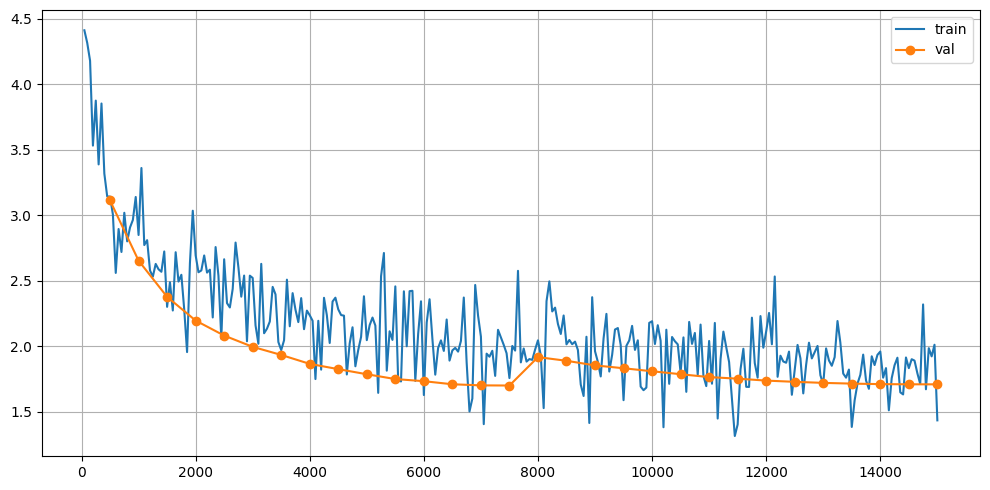

In [10]:
import matplotlib.pyplot as plt
final_val_loss = evaluate(val_loader, max_batches=200)
final_val_ppl = math.exp(final_val_loss)
print("final val loss", final_val_loss, "ppl", final_val_ppl)

plt.figure(figsize=(10, 5))
plt.plot(step_history, train_loss_history, label="train")
if val_loss_history:
    vs, vl = zip(*val_loss_history); plt.plot(vs, vl, label="val", marker="o")
plt.legend(); plt.grid(True); plt.tight_layout(); plt.savefig(LOSS_PLOT_PATH, dpi=200); plt.show()

torch.save({"state_dict": raw_model.state_dict(),
            "config": {"vocab_size": VOCAB_SIZE, "d_model": D_MODEL, "n_layers": N_LAYERS, "n_heads": N_HEADS,
                       "d_ff": D_FF, "max_seq_len": BLOCK_SIZE, "dropout": DROPOUT, "kv_heads": KV_HEADS,
                       "rope_base": ROPE_BASE, "arch_name": ARCH_NAME, "step": step}}, MODEL_PATH)

In [11]:
CTX = BLOCK_SIZE - 1                                                            

@torch.no_grad()
def generate_batch(id_lists, temperature=0.6, top_p=0.9, top_k=50, rep_pen=1.1, rep_window=200,
                   max_new=MAX_GENERATION_TOKENS, target_words=TARGET_GENERATION_WORDS):
    """id_lists: list of equal-length token-id lists. Returns list of decoded strings (<= target_words words)."""
    raw_model.eval()
    B = len(id_lists)
    idx = torch.tensor(id_lists, dtype=torch.long, device=DEVICE)
    gen = torch.empty((B, 0), dtype=torch.long, device=DEVICE)
    eos_count = torch.zeros(B, dtype=torch.long, device=DEVICE)
    use_cuda = DEVICE.type == "cuda"
    for _ in range(max_new):
        ctx = idx[:, -CTX:]
        with torch.autocast(device_type="cuda", enabled=use_cuda):
            logits = raw_model.last_logits(ctx)
        logits = logits.float()

        if rep_pen != 1.0 and gen.size(1) > 0:
            eos_logit = logits[:, EOS_ID].clone()
            recent = gen[:, -rep_window:]
            sc = torch.gather(logits, 1, recent)
            sc = torch.where(sc > 0, sc / rep_pen, sc * rep_pen)
            logits.scatter_(1, recent, sc)
            logits[:, EOS_ID] = eos_logit                                                     
        logits[:, BAD_IDS] = float("-inf")
        logits[idx[:, -1] == EOS_ID, EOS_ID] = float("-inf")                                

        if temperature <= 0:
            nxt = logits.argmax(dim=-1, keepdim=True)
        else:
            logits = logits / temperature
            if top_k and top_k > 0:
                kth = torch.topk(logits, min(top_k, logits.size(-1))).values[:, -1:]
                logits = logits.masked_fill(logits < kth, float("-inf"))
            probs = torch.softmax(logits, dim=-1)
            sp, si = torch.sort(probs, descending=True, dim=-1)
            remove = (torch.cumsum(sp, dim=-1) - sp) > top_p
            sp = sp.masked_fill(remove, 0.0)
            sp = sp / sp.sum(dim=-1, keepdim=True)
            nxt = torch.gather(si, -1, torch.multinomial(sp, 1))

        idx = torch.cat([idx, nxt], dim=1)
        gen = torch.cat([gen, nxt], dim=1)
        eos_count += (nxt.squeeze(1) == EOS_ID).long()
        if bool((eos_count >= target_words + 1).all()):
            break
    outs = []
    for row in gen.tolist():
        outs.append(" ".join(tokenizer.decode(row).split()[:target_words]))
    return outs

_enc_cache = {}
def generate_for_dataset(prompt_dict, cfg, ids=None, verbose=True):
    ids = list(prompt_dict.keys()) if ids is None else ids
    enc = {}
    for k in ids:
        text = prompt_dict[k]["text"]
        if text not in _enc_cache:
            _enc_cache[text] = tokenizer.encode(text)[-CTX:]
        enc[k] = _enc_cache[text]
    buckets = {}
    for k in ids: buckets.setdefault(len(enc[k]), []).append(k)                                                              
    preds, done = {}, 0
    for L, ks in buckets.items():
        for s in range(0, len(ks), GEN_BATCH):
            chunk = ks[s:s + GEN_BATCH]
            texts = generate_batch([enc[k] for k in chunk], **cfg)
            for k, t in zip(chunk, texts): preds[k] = {"text": t}
            done += len(chunk)
            if verbose: print(f"  generated {done}/{len(ids)}")
    return {k: preds[k] for k in ids}                   

In [12]:
def bertscore_f1(truth_path, pred_path):
    """Official script if available (parse its output), else bert_score package directly."""
    if os.path.exists(EVAL_SCRIPT):
        r = subprocess.run(["python", EVAL_SCRIPT, "--truth", truth_path, "--prediction", pred_path], capture_output=True, text=True)
        out = r.stdout + "\n" + r.stderr
        for line in out.splitlines():
            if "bert" in line.lower():
                nums = re.findall(r"-?\d+\.\d+", line)
                if nums: return float(nums[-1]), out
        return None, out
    from bert_score import score as bs
    t = json.load(open(truth_path)); p = json.load(open(pred_path))
    ks = [k for k in t if k in p]
    _, _, F1 = bs([p[k]["text"] for k in ks], [t[k]["text"] for k in ks], lang="en", verbose=False)
    return float(F1.mean()), "bert_score package"

GRID_N = 48
grid_ids = list(heldout_prompts.keys())[:GRID_N]
grid_truth = {k: heldout_truth[k] for k in grid_ids}
GRID_TRUTH_PATH = os.path.join(OUTPUT_DIR, "grid_truth.json")
json.dump(grid_truth, open(GRID_TRUTH_PATH, "w"))

GRID = [
    dict(temperature=0.8, top_p=0.95, top_k=0,  rep_pen=1.0),                                 
    dict(temperature=0.0, top_p=1.0,  top_k=0,  rep_pen=1.0),           
    dict(temperature=0.0, top_p=1.0,  top_k=0,  rep_pen=1.15),                               
    dict(temperature=0.5, top_p=0.9,  top_k=50, rep_pen=1.0),
    dict(temperature=0.5, top_p=0.9,  top_k=50, rep_pen=1.1),
    dict(temperature=0.6, top_p=0.9,  top_k=50, rep_pen=1.1),
    dict(temperature=0.7, top_p=0.95, top_k=50, rep_pen=1.1),
]
grid_results = []
for cfg in GRID:
    t_start = time.time()
    torch.manual_seed(SEED)
    preds = generate_for_dataset(heldout_prompts, cfg, ids=grid_ids, verbose=False)
    pp = os.path.join(OUTPUT_DIR, "grid_pred.json"); json.dump(preds, open(pp, "w"))
    f1, raw = bertscore_f1(GRID_TRUTH_PATH, pp)
    grid_results.append((f1, cfg))
    print(f"BERTScore-F1={f1} | {cfg} | {time.time()-t_start:.0f}s")
print(raw[-600:])

valid = [r for r in grid_results if r[0] is not None]
BEST_CFG = max(valid, key=lambda r: r[0])[1] if valid else dict(temperature=0.6, top_p=0.9, top_k=50, rep_pen=1.1)
print("BEST decoding config:", BEST_CFG)
                                                                                                            

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.42GB            

... (18 outputs left out)

BERTScore-F1=0.8643700480461121 | {'temperature': 0.6, 'top_p': 0.9, 'top_k': 50, 'rep_pen': 1.1} | 160s


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERTScore-F1=0.86500483751297 | {'temperature': 0.7, 'top_p': 0.95, 'top_k': 50, 'rep_pen': 1.1} | 166s
bert_score package
BEST decoding config: {'temperature': 0.5, 'top_p': 0.9, 'top_k': 50, 'rep_pen': 1.1}


In [13]:
                                                                                                
torch.manual_seed(SEED)
heldout_preds = generate_for_dataset(heldout_prompts, BEST_CFG)
json.dump(heldout_preds, open(HELDOUT_PRED_PATH, "w"), ensure_ascii=False, indent=2)
f1_full, raw_full = bertscore_f1(HELDOUT_TRUTH_PATH, HELDOUT_PRED_PATH)
print("full held-out BERTScore F1:", f1_full); print(raw_full[-800:])
print(np.mean([len(v["text"].split()) for v in heldout_preds.values()]), "avg words per continuation")

  generated 16/74
  generated 32/74
  generated 48/74
  generated 64/74
  generated 74/74


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


full held-out BERTScore F1: 0.8534170389175415
bert_score package
128.0 avg words per continuation


In [14]:
                                     
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)
torch.manual_seed(SEED)
official_predictions = generate_for_dataset(test_data, BEST_CFG)
assert set(official_predictions) == set(test_data), "ID mismatch"
print("min/avg words:", min(len(v["text"].split()) for v in official_predictions.values()),
      np.mean([len(v["text"].split()) for v in official_predictions.values()]))
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(official_predictions, f, ensure_ascii=False, indent=2)
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    zf.write(PREDICTION_PATH, arcname="prediction.json")
print("Submit this:", SUBMISSION_ZIP)

  generated 16/1000
  generated 32/1000
  generated 48/1000
  generated 64/1000
  generated 80/1000
  generated 96/1000
  generated 112/1000
  generated 128/1000
  generated 144/1000
  generated 160/1000
  generated 176/1000
  generated 192/1000
  generated 208/1000
  generated 224/1000
  generated 240/1000
  generated 256/1000
  generated 272/1000
  generated 288/1000
  generated 304/1000
  generated 320/1000
  generated 336/1000
  generated 352/1000
  generated 368/1000
  generated 384/1000
  generated 400/1000
  generated 416/1000
  generated 432/1000
  generated 448/1000
  generated 464/1000
  generated 480/1000
  generated 496/1000
  generated 512/1000
  generated 528/1000
  generated 544/1000
  generated 560/1000
  generated 576/1000
  generated 592/1000
  generated 608/1000
  generated 624/1000
  generated 640/1000
  generated 656/1000
  generated 672/1000
  generated 688/1000
  generated 704/1000
  generated 720/1000
  generated 736/1000
  generated 752/1000
  generated 768/100

In [15]:
row = {"run_id": RUN_ID + "_resume15k", "arch": ARCH_NAME, "data_sources": ";".join(DATA_SOURCES), "vocab_size": VOCAB_SIZE,
       "train_tokens": len(train_ids), "block_size": BLOCK_SIZE, "d_model": D_MODEL, "n_layers": N_LAYERS, "n_heads": N_HEADS,
       "kv_heads": KV_HEADS, "d_ff": D_FF, "params_M": round(n_params / 1e6, 2), "train_steps": step,
       "final_val_loss": round(final_val_loss, 6), "final_val_ppl": round(final_val_ppl, 4),
       "training_hours": round(training_time / 3600, 3), "heldout_bertscore": f1_full, "decoding": json.dumps(BEST_CFG)}
write_header = not os.path.exists(LOG_PATH)
with open(LOG_PATH, "a", newline="") as f:
    w = csv.DictWriter(f, fieldnames=list(row.keys()))
    if write_header: w.writeheader()
    w.writerow(row)
print(row)

{'run_id': 'rope_mqa_swiglu_train_supreme_court-train_acts-train_high_courts-train_tribunals_resume15k', 'arch': 'rope_mqa_swiglu', 'data_sources': 'Phase_1_Pretraining/Train/train_supreme_court.json;Phase_1_Pretraining/Train/train_acts.json;Phase_1_Pretraining/Train/train_high_courts.json;Phase_1_Pretraining/Train/train_tribunals.json', 'vocab_size': 12000, 'train_tokens': 300000000, 'block_size': 512, 'd_model': 768, 'n_layers': 12, 'n_heads': 12, 'kv_heads': 1, 'd_ff': 3072, 'params_M': 109.51, 'train_steps': 15000, 'final_val_loss': 1.701793, 'final_val_ppl': 5.4838, 'training_hours': 2.003, 'heldout_bertscore': 0.8534170389175415, 'decoding': '{"temperature": 0.5, "top_p": 0.9, "top_k": 50, "rep_pen": 1.1}'}
